<a href="https://colab.research.google.com/github/DrinV9/ai_usage_vs_occupation_pay/blob/main/ai_usage_vs_occupation_pay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Is AI usage concentrated in higher-paying occupations?

## Step 1: Load the data
Each row is a job task, and `pct` is that task's share of all usage in the Anthropic Economic Index. The shares add up to 100.

In [1]:
import pandas as pd
usage = pd.read_csv("task_pct_v2.csv")
print(usage.shape)
print(usage["pct"].sum())
usage.sort_values("pct", ascending=False).head(10)


(3365, 2)
99.99999999999983


,task_name,pct
1916,"modify existing software to correct errors, to...",6.650740
1228,"diagnose, troubleshoot, and resolve hardware, ...",2.815939
1915,"modify existing software to correct errors, al...",2.678619
750,correct errors by making appropriate changes a...,2.455127
3364,"write, update, and maintain computer programs ...",2.397919
919,"design, build, or maintain web sites, using au...",2.361766
3358,"write, analyze, review, and rewrite programs, ...",2.190141
1967,none,1.781672
3319,"write original or adapted material for dramas,...",0.892531
2931,review class material with students by discuss...,0.874043


In [2]:
onet = pd.read_csv("onet_task_statements.csv")
print(onet.shape)
print(list(onet.columns))
onet.head()

(19530, 8)
['O*NET-SOC Code', 'Title', 'Task ID', 'Task', 'Task Type', 'Incumbents Responding', 'Date', 'Domain Source']


,O*NET-SOC Code,Title,Task ID,Task,Task Type,Incumbents Responding,Date,Domain Source
0,11-1011.00,Chief Executives,8823,Direct or coordinate an organization's financi...,Core,87.0,07/2014,Incumbent
1,11-1011.00,Chief Executives,8831,Appoint department heads or managers and assig...,Core,87.0,07/2014,Incumbent
2,11-1011.00,Chief Executives,8825,Analyze operations to evaluate performance of ...,Core,87.0,07/2014,Incumbent
3,11-1011.00,Chief Executives,8826,"Direct, plan, or implement policies, objective...",Core,87.0,07/2014,Incumbent
4,11-1011.00,Chief Executives,8827,"Prepare budgets for approval, including those ...",Core,87.0,07/2014,Incumbent


## Step 2: Match tasks to occupations
Remove the "none" row, then link each task to its occupations using the O*NET file. If a task belongs to several occupations, its usage is split evenly between them (an assumption).

In [3]:
# 1. Remove the "none" row
usage = usage[usage["task_name"] != "none"].copy()

# 2. Make the task text comparable
usage["task_key"] = usage["task_name"].str.lower().str.strip()
onet["task_key"] = onet["Task"].str.lower().str.strip()

# 3. How many usage tasks can be found in the O*NET file?
print("Share of usage tasks found in O*NET:", usage["task_key"].isin(onet["task_key"]).mean())

# 4. Match each task to its occupation(s)
onet_small = onet[["task_key", "O*NET-SOC Code", "Title"]].drop_duplicates()
tasks = usage.merge(onet_small, on="task_key", how="inner")

# 5. If a task belongs to several occupations, split its usage evenly between them
tasks["n_occ"] = tasks.groupby("task_key")["O*NET-SOC Code"].transform("nunique")
tasks["pct_share"] = tasks["pct"] / tasks["n_occ"]

print("Matched rows:", len(tasks))
print("Total pct kept:", tasks["pct_share"].sum())
tasks.head()

Share of usage tasks found in O*NET: 1.0
Matched rows: 4086
Total pct kept: 98.21832799937538


,task_name,pct,task_key,O*NET-SOC Code,Title,n_occ,pct_share
0,accept commissions to create music for special...,0.002054,accept commissions to create music for special...,27-2041.04,Music Composers and Arrangers,1,0.002054
1,act as advisers to student organizations.,0.004827,act as advisers to student organizations.,25-1011.00,"Business Teachers, Postsecondary",34,0.000142
2,act as advisers to student organizations.,0.004827,act as advisers to student organizations.,25-1021.00,"Computer Science Teachers, Postsecondary",34,0.000142
3,act as advisers to student organizations.,0.004827,act as advisers to student organizations.,25-1022.00,"Mathematical Science Teachers, Postsecondary",34,0.000142
4,act as advisers to student organizations.,0.004827,act as advisers to student organizations.,25-1031.00,"Architecture Teachers, Postsecondary",34,0.000142


## Step 3: Total usage per occupation
Add up each occupation's share of usage. Occupation codes are shortened to 6 digits so they match the BLS wage data.

In [4]:
# Add up usage per occupation (6-digit SOC code, e.g. 25-1011)
# Use the main occupation title (the code ending in .00) as the label
main_titles = (
    onet[onet["O*NET-SOC Code"].str.endswith(".00")]
    .assign(soc_code=lambda d: d["O*NET-SOC Code"].str[:7])
    [["soc_code", "Title"]]
    .drop_duplicates("soc_code")
    .rename(columns={"Title": "main_title"})
)

tasks["soc_code"] = tasks["O*NET-SOC Code"].str[:7]

occ_usage = (
    tasks.groupby("soc_code")
    .agg(ai_usage_pct=("pct_share", "sum"), n_onet_codes=("O*NET-SOC Code", "nunique"))
    .reset_index()
    .merge(main_titles, on="soc_code", how="left")
)

occ_usage["title"] = occ_usage["main_title"].fillna("(no main title)")
print(len(occ_usage), "occupations")
occ_usage.sort_values("ai_usage_pct", ascending=False).head(15)

588 occupations


,soc_code,ai_usage_pct,n_onet_codes,main_title,title
67,15-1131,7.506501,1,Computer Programmers,Computer Programmers
76,15-1199,7.131156,12,NaN,(no main title)
69,15-1133,7.007735,1,"Software Developers, Systems Software","Software Developers, Systems Software"
70,15-1134,4.496187,1,Web Developers,Web Developers
68,15-1132,3.574419,1,"Software Developers, Applications","Software Developers, Applications"
72,15-1142,3.003895,1,Network and Computer Systems Administrators,Network and Computer Systems Administrators
226,25-3099,2.141868,1,NaN,(no main title)
462,43-9111,1.829637,2,Statistical Assistants,Statistical Assistants
65,15-1121,1.784137,2,Computer Systems Analysts,Computer Systems Analysts
234,25-9031,1.672391,2,Instructional Coordinators,Instructional Coordinators


## Step 4: Load BLS wages
Median annual wages by occupation, from the May 2018 BLS OEWS file. I used 2018 because its occupation codes match the Anthropic and O*NET data.

In [5]:
wages18 = pd.read_excel("national_M2018_dl.xlsx")
wages18.columns = wages18.columns.str.upper()
print(list(wages18.columns))
print(wages18[wages18["OCC_CODE"].str.startswith("15-11")][["OCC_CODE", "OCC_TITLE"]])

['OCC_CODE', 'OCC_TITLE', 'OCC_GROUP', 'TOT_EMP', 'EMP_PRSE', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']
    OCC_CODE                                          OCC_TITLE
127  15-1100                               Computer Occupations
128  15-1110       Computer and Information Research Scientists
129  15-1111       Computer and Information Research Scientists
130  15-1120                  Computer and Information Analysts
131  15-1121                          Computer Systems Analysts
132  15-1122                      Information Security Analysts
133  15-1130                Software Developers and Programmers
134  15-1131                               Computer Programmers
135  15-1132                  Software Developers, Applications
136  15-1133              Software Developers, Systems Software
137  15-1134                                     Web Developers
138  

## Step 5: Merge usage with wages
Join the two datasets on occupation code and check how much usage found a matching wage (about 96.5%).

In [6]:
# Keep only detailed occupations, and clean the wage column
wages_d = wages18[wages18["OCC_GROUP"] == "detailed"].copy()
wages_d["median_wage"] = pd.to_numeric(
    wages_d["A_MEDIAN"].replace("#", 208000), errors="coerce"
)
wages_d = wages_d[["OCC_CODE", "OCC_TITLE", "median_wage"]].rename(
    columns={"OCC_CODE": "soc_code", "OCC_TITLE": "wage_title"}
)

# Merge usage with wages
df = occ_usage.merge(wages_d, on="soc_code", how="left", indicator=True)

print(df["_merge"].value_counts())
matched = df["_merge"] == "both"
print("Share of AI usage that matched a wage:",
      df.loc[matched, "ai_usage_pct"].sum() / df["ai_usage_pct"].sum())

# Which high-usage occupations still didn't match?
df[~matched].sort_values("ai_usage_pct", ascending=False)[
    ["soc_code", "title", "ai_usage_pct"]
].head(10)

_merge
both          570
left_only      18
right_only      0
Name: count, dtype: int64
Share of AI usage that matched a wage: 0.9652625932118845


,soc_code,title,ai_usage_pct
226,25-3099,(no main title),2.141868
158,21-1014,Mental Health Counselors,0.452993
81,15-2091,Mathematical Technicians,0.182820
299,29-2011,Medical and Clinical Laboratory Technologists,0.112876
116,19-1020,(no main title),0.110103
300,29-2012,Medical and Clinical Laboratory Technicians,0.099524
388,39-7011,Tour Guides and Escorts,0.066760
155,21-1011,Substance Abuse and Behavioral Disorder Counse...,0.057054
389,39-7012,Travel Guides,0.047656
36,13-1023,"Purchasing Agents, Except Wholesale, Retail, a...",0.036256


## Step 6: Main results
How AI usage relates to pay across all occupations: a scatter plot, two correlation measures, and usage by wage quarter.

568 occupations with usage and wage


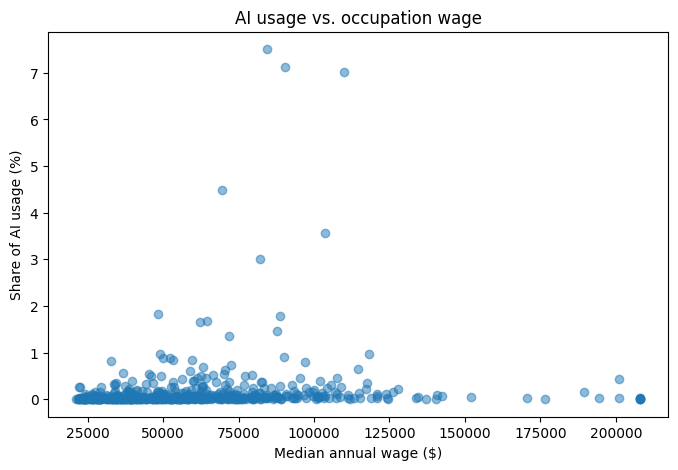

Pearson correlation:  0.12220254085905696
Spearman correlation: 0.32911921941801986
wage_group
Lowest 25%      7.4
Lower-mid      15.7
Upper-mid      25.7
Highest 25%    51.2
Name: ai_usage_pct, dtype: float64


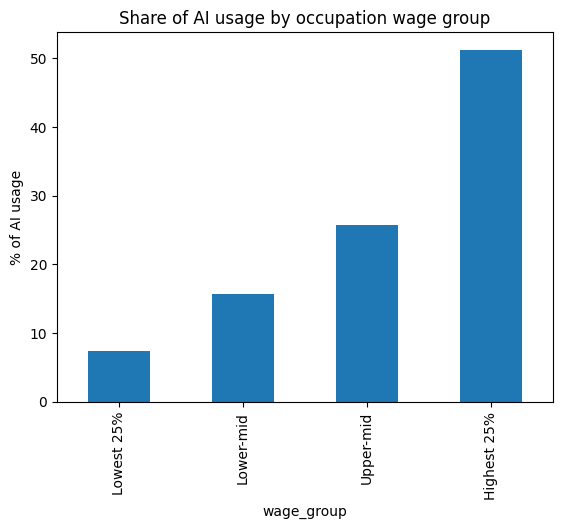

In [7]:
import matplotlib.pyplot as plt

# Keep only occupations that have both usage and a wage
d = df[df["_merge"] == "both"].dropna(subset=["median_wage"]).copy()
print(len(d), "occupations with usage and wage")

# Chart 1: every occupation as a dot
plt.figure(figsize=(8, 5))
plt.scatter(d["median_wage"], d["ai_usage_pct"], alpha=0.5)
plt.xlabel("Median annual wage ($)")
plt.ylabel("Share of AI usage (%)")
plt.title("AI usage vs. occupation wage")
plt.show()

# Two ways of measuring the relationship
print("Pearson correlation: ", d["median_wage"].corr(d["ai_usage_pct"]))
print("Spearman correlation:", d["median_wage"].corr(d["ai_usage_pct"], method="spearman"))

# Chart 2: how is usage split across wage groups?
d["wage_group"] = pd.qcut(d["median_wage"], 4,
                          labels=["Lowest 25%", "Lower-mid", "Upper-mid", "Highest 25%"])
share = d.groupby("wage_group", observed=True)["ai_usage_pct"].sum()
print((share / share.sum() * 100).round(1))
(share / share.sum() * 100).plot(kind="bar")
plt.ylabel("% of AI usage")
plt.title("Share of AI usage by occupation wage group")
plt.show()

## Which occupations drive the result?
The ten occupations with the most usage. Most are computer jobs.

In [8]:
# 1. Which occupations drive the result?
d.sort_values("ai_usage_pct", ascending=False).head(10)[
    ["soc_code", "wage_title", "ai_usage_pct", "median_wage"]
]

,soc_code,wage_title,ai_usage_pct,median_wage
67,15-1131,Computer Programmers,7.506501,84280.0
76,15-1199,"Computer Occupations, All Other",7.131156,90270.0
69,15-1133,"Software Developers, Systems Software",7.007735,110000.0
70,15-1134,Web Developers,4.496187,69430.0
68,15-1132,"Software Developers, Applications",3.574419,103620.0
72,15-1142,Network and Computer Systems Administrators,3.003895,82050.0
462,43-9111,Statistical Assistants,1.829637,48330.0
65,15-1121,Computer Systems Analysts,1.784137,88740.0
234,25-9031,Instructional Coordinators,1.672391,64450.0
260,27-3043,Writers and Authors,1.650514,62170.0


## Usage by wage band
Share of usage in each wage range, to check the shape of the relationship.

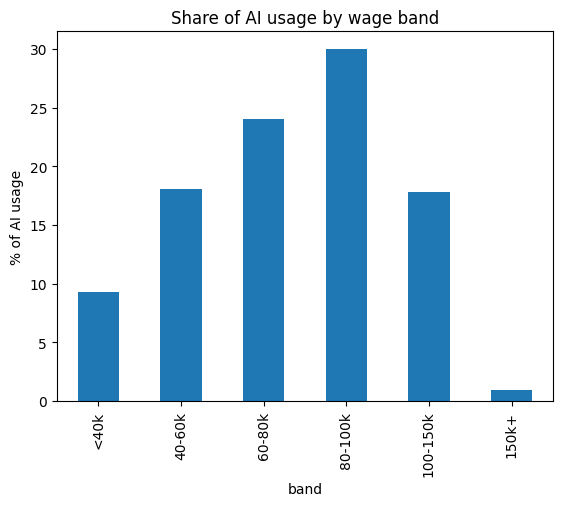

In [9]:
# 2. Usage by wage band, to see the hump shape directly
d["band"] = pd.cut(d["median_wage"],
                   [0, 40000, 60000, 80000, 100000, 150000, 250000],
                   labels=["<40k", "40-60k", "60-80k", "80-100k", "100-150k", "150k+"])
b = d.groupby("band", observed=True)["ai_usage_pct"].sum()
(b / b.sum() * 100).round(1).plot(kind="bar")
plt.ylabel("% of AI usage")
plt.title("Share of AI usage by wage band")
plt.show()

## Robustness check: excluding computer occupations
Repeating the analysis without computer occupations (codes starting 15-1) to see whether the pattern depends on them.

In [10]:
d_no = d[~d["soc_code"].str.startswith("15-1")].copy()
print("Occupations left:", len(d_no))
print("Pearson: ", d_no["median_wage"].corr(d_no["ai_usage_pct"]))
print("Spearman:", d_no["median_wage"].corr(d_no["ai_usage_pct"], method="spearman"))

d_no["wage_group"] = pd.qcut(d_no["median_wage"], 4,
                             labels=["Lowest 25%", "Lower-mid", "Upper-mid", "Highest 25%"])
s = d_no.groupby("wage_group", observed=True)["ai_usage_pct"].sum()
print((s / s.sum() * 100).round(1))

Occupations left: 555
Pearson:  0.08518931576704893
Spearman: 0.3034770543119026
wage_group
Lowest 25%     12.1
Lower-mid      25.7
Upper-mid      33.9
Highest 25%    28.3
Name: ai_usage_pct, dtype: float64
